# Decision Trees

*Twenty questions, played by a computer: how a model can learn to make decisions by asking one simple question at a time.*

:::{admonition} What we are going to do
:class: tip
Almost every model we have met so far has been an **equation**: a line, a polynomial, a kernel. This chapter is about a model that is a **flowchart** instead.

A **decision tree** makes a prediction by asking a short series of yes/no questions about a sample ("Is the carbon content above 0.5 wt%?", "Was it annealed below 850 °C?") until it reaches an answer. We will see

1. how a tree is put together (root, branches, leaves),
2. how the computer decides **which question to ask first**, using a number called the **Gini impurity**,
3. why a tree that keeps asking questions forever is a bad idea (our old friend, **overfitting**), and
4. how to grow a sensible tree in `scikit-learn`.

In the next chapter, we will plant many trees together to make a **random forest**.
:::

## A tree is just a list of questions

In the preview for this week you met a "where should I have lunch?" tree. A machine-learning tree works the same way. The vocabulary is borrowed from real trees, except our trees grow **upside down**:

- **Root node** - the first question, asked of *every* sample. It sits at the top.
- **Decision node** (internal node) - any later question.
- **Branch** - the path you follow after answering yes or no.
- **Leaf node** - an end point. No more questions; the leaf gives the prediction.

A question can be about a **numerical** feature ("Is the yield strength ≤ 400 MPa?") or a **categorical** one ("Is the crystal structure FCC?"). Either way, each question looks at **one feature at a time** and splits the samples into two groups. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, cross_val_score

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
RED, BLUE, LINE, GOLD, GREEN = "#c8463d", "#2f6db3", "#243b53", "#e0a12a", "#4a9d5b"
LIGHT = {0: "#f6d5d2", 1: "#d3e2f4"}          # light red / light blue backgrounds

# ---- the 20-point teaching example (made-up coordinates that follow the lecture sketch) ----
red  = [(-26, 21), (-16, 10), (-29, -1), (-3, 24), (19, 24), (33, 15), (27, 12), (31, -6)]
blue = [(9, 19), (-2, 14), (14, 15), (5, 11), (-8, 9), (5, 5), (14, 6), (-2, 2),
        (-5, -4), (14, -3), (11, -6), (-2, -10)]
X_toy = np.array(red + blue, dtype=float)
y_toy = np.array([0] * len(red) + [1] * len(blue))     # 0 = red, 1 = blue

def scatter_toy(ax, s=55):
    ax.scatter(*np.array(red).T,  color=RED,  s=s, edgecolor="white", lw=0.7, zorder=3, label="red (8)")
    ax.scatter(*np.array(blue).T, color=BLUE, s=s, edgecolor="white", lw=0.7, zorder=3, label="blue (12)")
    ax.axhline(0, color="#bbbbbb", lw=0.8, zorder=1); ax.axvline(0, color="#bbbbbb", lw=0.8, zorder=1)
    ax.set_xlim(-34, 38); ax.set_ylim(-14, 29); ax.set_xlabel("x"); ax.set_ylabel("y")

def box(ax, x, y, text, fc="white", ec=LINE, fs=9.5):
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, zorder=3,
            bbox=dict(boxstyle="round,pad=0.45", fc=fc, ec=ec, lw=1.2))

def arrow(ax, p, q, label):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=LINE, lw=1.1,
                shrinkA=17, shrinkB=17), zorder=2)
    ax.text((p[0] + q[0]) / 2 + (-0.035 if label == "Yes" else 0.035), (p[1] + q[1]) / 2, label,
            ha="center", va="center", fontsize=9, color=GREEN if label == "Yes" else RED)

def plot_regions(ax, model, X, y, h=300, pad=0.5, alpha=0.35, s=18):
    x0, x1 = X[:, 0].min() - pad, X[:, 0].max() + pad
    y0, y1 = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x0, x1, h), np.linspace(y0, y1, h))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=[GOLD, GREEN], alpha=alpha)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(y == 0, GOLD, GREEN), s=s, edgecolor="white", lw=0.4)
    ax.set_xticks([]); ax.set_yticks([])

## A worked example: red versus blue

Here are 20 data points with two features, $x$ and $y$. There are 8 **red** points and 12 **blue** points. (The coordinates are made up for teaching, following the sketch used in the lecture.)

Try to separate them with **one** straight line. 

Well, you can't: the blue points sit in the middle, and the red points surround them. But we *can* separate them with a few simple questions, asked one after the other.

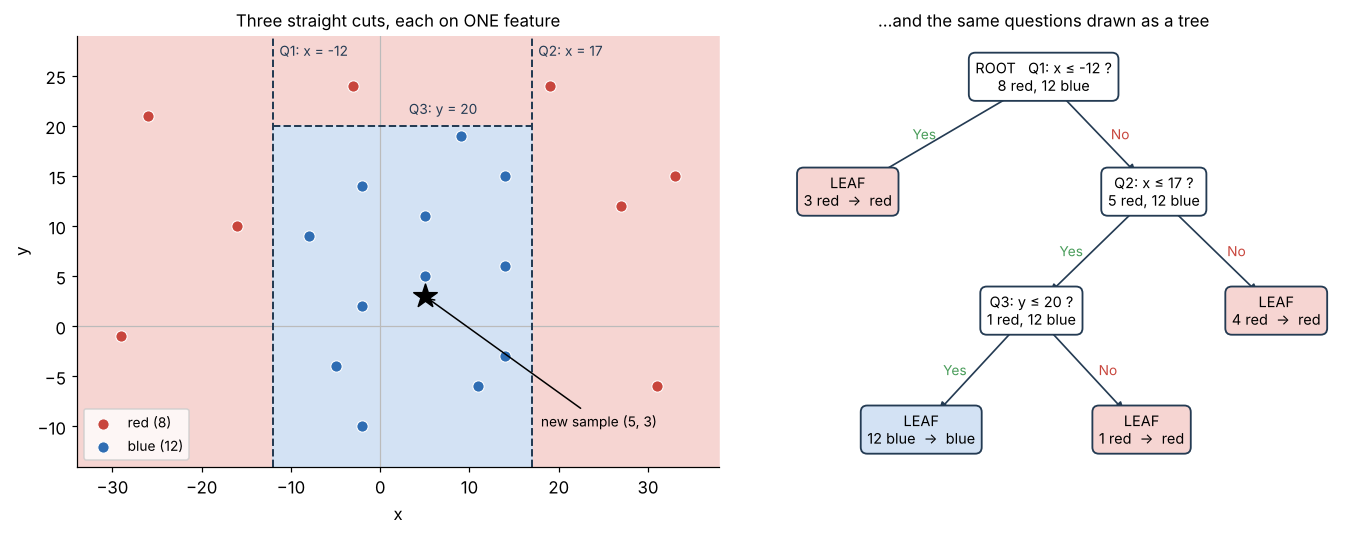

In [2]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 5.0), gridspec_kw={"width_ratios": [1.05, 1]})

# left: the data, the three cuts and the final regions
a.fill_between([-34, -12], -14, 29, color=LIGHT[0], zorder=0)
a.fill_between([17, 38], -14, 29, color=LIGHT[0], zorder=0)
a.fill_between([-12, 17], 20, 29, color=LIGHT[0], zorder=0)
a.fill_between([-12, 17], -14, 20, color=LIGHT[1], zorder=0)
a.plot([-12, -12], [-14, 29], "--", color=LINE, lw=1.3)
a.plot([17, 17], [-14, 29], "--", color=LINE, lw=1.3)
a.plot([-12, 17], [20, 20], "--", color=LINE, lw=1.3)
for (tx, ty, t) in [(-12, 27, "Q1: x = -12"), (17, 27, "Q2: x = 17"), (2.5, 21.2, "Q3: y = 20")]:
    a.text(tx + 0.7, ty, t, fontsize=9, color=LINE)
scatter_toy(a)
a.scatter([5], [3], marker="*", s=260, color="black", zorder=4)
a.annotate("new sample (5, 3)", xy=(5, 3), xytext=(18, -10), fontsize=9,
           arrowprops=dict(arrowstyle="->", color="black"))
a.legend(loc="lower left", fontsize=9, frameon=True)
a.set_title("Three straight cuts, each on ONE feature", fontsize=11)

# right: the same thing drawn as a tree
b.set_xlim(0, 1); b.set_ylim(-0.05, 1.0); b.axis("off")
P = {"r": (0.50, 0.90), "L1": (0.18, 0.62), "n2": (0.68, 0.62), "n3": (0.48, 0.33),
     "L4": (0.88, 0.33), "L5": (0.30, 0.04), "L6": (0.66, 0.04)}
arrow(b, P["r"], P["L1"], "Yes"); arrow(b, P["r"], P["n2"], "No")
arrow(b, P["n2"], P["n3"], "Yes"); arrow(b, P["n2"], P["L4"], "No")
arrow(b, P["n3"], P["L5"], "Yes"); arrow(b, P["n3"], P["L6"], "No")
box(b, *P["r"], "ROOT   Q1: x ≤ -12 ?\n8 red, 12 blue")
box(b, *P["n2"], "Q2: x ≤ 17 ?\n5 red, 12 blue")
box(b, *P["n3"], "Q3: y ≤ 20 ?\n1 red, 12 blue")
box(b, *P["L1"], "LEAF\n3 red  →  red", fc=LIGHT[0])
box(b, *P["L4"], "LEAF\n4 red  →  red", fc=LIGHT[0])
box(b, *P["L5"], "LEAF\n12 blue  →  blue", fc=LIGHT[1])
box(b, *P["L6"], "LEAF\n1 red  →  red", fc=LIGHT[0])
b.set_title("…and the same questions drawn as a tree", fontsize=11)
plt.tight_layout(); plt.show()

Let's walk down the tree:

1. **Root (Q1): is $x \le -12$?** All 20 points start here. *Yes* sends 3 red points to the left; *No* sends the other 5 red and all 12 blue points to the right.
2. The left group is all red. A group that contains only one class is called **pure**, and a pure group needs no more questions. It becomes a **leaf**.
3. **Q2: is $x \le 17$?** The right group is still mixed, so we ask another question. *No* gives 4 red points (pure, another leaf). *Yes* leaves 1 red and 12 blue.
4. **Q3: is $y \le 20$?** This separates the 12 blue points from the single red one. Every leaf is now pure, so we stop.

**Making a prediction.** A new sample arrives at $(5, 3)$, but we don't know whether it should be red or blue. So we start at the top and answer each question: Q1, is $5 \le -12$? *No*. Q2, is $5 \le 17$? *Yes*. Q3, is $3 \le 20$? *Yes*. We land in the "12 blue" leaf, so we predict **blue**.

## Many different trees fit the same data

The tree above is not the only one that works. We could have started with "is $x < 0$?" and still ended with pure leaves after a few more questions. With real data there are *thousands* of possible questions at every step. So depending on the order of questions we ask, we build trees that look different to each other.

So which tree should we prefer? Usually the one that reaches pure (or nearly pure) groups with **fewer questions**: a shorter tree is quicker to use and, as we will see, tends to behave better on new data. To choose between questions, the computer needs a way to **score** how well each one separates the classes.

:::{note} Trees only cut parallel to the axes
Because each question looks at a single feature, every cut is a straight line **parallel to an axis** ($x = \text{something}$ or $y = \text{something}$). A tree cannot draw a sloping line in one step. If the true boundary is diagonal, the tree has to build it as a **staircase** of small cuts, as the figure below shows. (Special "oblique" trees that cut along combinations of features do exist, but they are not what `scikit-learn` provides.)
:::

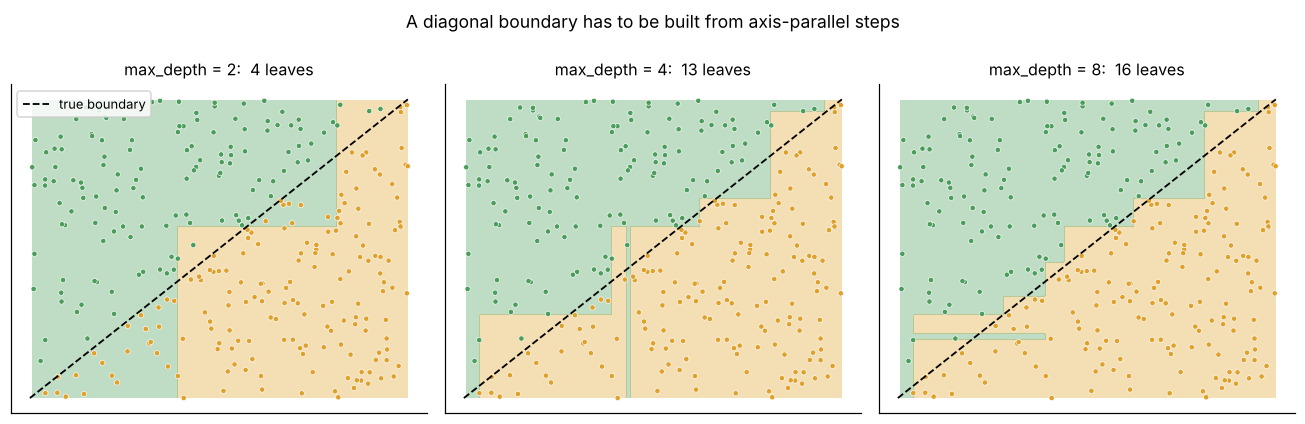

In [3]:
rng = np.random.default_rng(0)
Xd = rng.uniform(0, 1, size=(300, 2))
yd = (Xd[:, 1] > Xd[:, 0]).astype(int)                 # true boundary: the diagonal y = x
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), sharey=True)
for ax, depth in zip(axes, [2, 4, 8]):
    m = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xd, yd)
    plot_regions(ax, m, Xd, yd, pad=0.0, s=12)
    ax.plot([0, 1], [0, 1], "k--", lw=1.2, label="true boundary")
    ax.set_title(f"max_depth = {depth}:  {m.get_n_leaves()} leaves", fontsize=10.5)
axes[0].legend(fontsize=8.5, loc="upper left")
fig.suptitle("A diagonal boundary has to be built from axis-parallel steps", fontsize=11.5)
plt.tight_layout(); plt.show()

## Scoring a question: the Gini impurity

We want a number that says how **mixed** a group is. The most common one, and the default in `scikit-learn`, is the **Gini impurity**:

$$
G = 1 - \sum_{k} p_k^{\,2}
$$

where $p_k$ is the fraction of the group that belongs to class $k$. For our two classes this is simply

$$
G = 1 - p_{\text{red}}^{\,2} - p_{\text{blue}}^{\,2}.
$$

- A **pure** group (all one class) has $G = 0$.
- A **50/50** group of two classes has $G = 1 - 0.5^2 - 0.5^2 = 0.5$, the most mixed a two-class group can be.

A question splits a group into two children. We score the question by the **weighted average** of the children's impurities, weighting each child by its share of the samples. **Lower is better.**

**Question A: $x \le -12$.**

- Left child: 3 red, 0 blue → $G = 1 - (3/3)^2 - (0/3)^2 = 0$
- Right child: 5 red, 12 blue → $G = 1 - (5/17)^2 - (12/17)^2 = 120/289 \approx 0.415$
- Weighted: $\frac{3}{20}\times 0 + \frac{17}{20}\times 0.415 \approx \mathbf{0.353}$

**Question B: $x \le 17$.**

- Left child: 4 red, 12 blue → $G = 1 - (4/16)^2 - (12/16)^2 = 0.375$
- Right child: 4 red, 0 blue → $G = 0$
- Weighted: $\frac{16}{20}\times 0.375 + \frac{4}{20}\times 0 = \mathbf{0.300}$

Question B scores lower, so it makes **purer** groups. A computer that tries every possible question will therefore start with $x \le 17$, not $x \le -12$. Below we let it try every cut on $x$ and on $y$ and plot the score for each one.

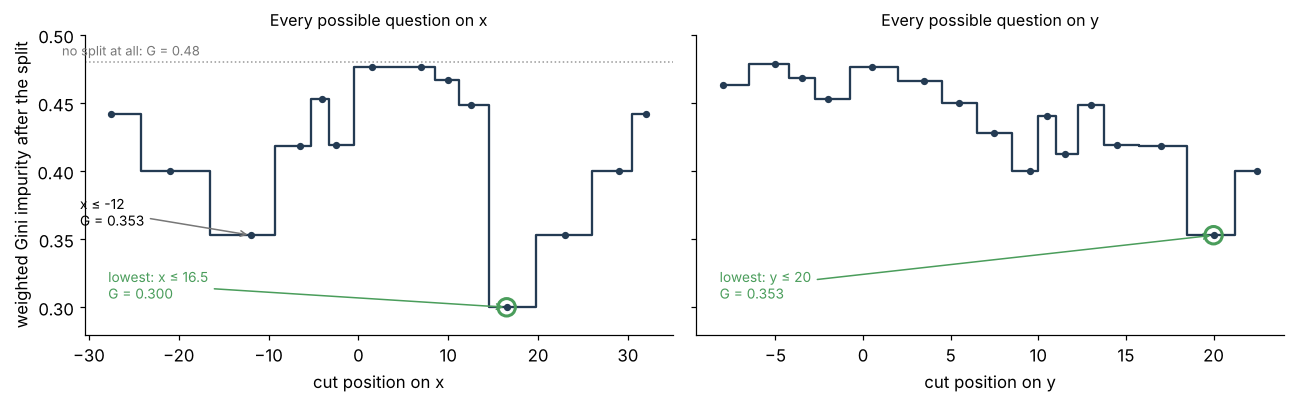

In [4]:
def weighted_gini(mask, y):
    total = 0.0
    for m in (mask, ~mask):
        p = y[m].mean()
        total += m.sum() / len(y) * (1 - p**2 - (1 - p)**2)
    return total

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for j, (ax, name) in enumerate(zip(axes, ["x", "y"])):
    v = np.unique(X_toy[:, j]); cuts = (v[:-1] + v[1:]) / 2      # midpoints, as scikit-learn uses
    g = [weighted_gini(X_toy[:, j] <= c, y_toy) for c in cuts]
    ax.step(cuts, g, where="mid", color=LINE, lw=1.5)
    ax.scatter(cuts, g, color=LINE, s=14, zorder=3)
    best = int(np.argmin(g))
    ax.scatter(cuts[best], g[best], s=130, facecolor="none", edgecolor=GREEN, lw=2, zorder=4)
    ax.annotate(f"lowest: {name} ≤ {cuts[best]:g}\nG = {g[best]:.3f}", xy=(cuts[best], g[best]),
                xytext=(0.04, 0.12), textcoords="axes fraction", fontsize=9, color=GREEN,
                arrowprops=dict(arrowstyle="->", color=GREEN))
    ax.set_xlabel(f"cut position on {name}"); ax.set_title(f"Every possible question on {name}", fontsize=10.5)
axes[0].axhline(0.48, color="#999999", ls=":", lw=1)
axes[0].text(-33, 0.485, "no split at all: G = 0.48", fontsize=8.5, color="#777777")
gA = weighted_gini(X_toy[:, 0] <= -12, y_toy)
axes[0].annotate(f"x ≤ -12\nG = {gA:.3f}", xy=(-12, gA), xytext=(-31, 0.36), fontsize=9,
                 arrowprops=dict(arrowstyle="->", color="#777777"))
axes[0].set_ylabel("weighted Gini impurity after the split"); axes[0].set_ylim(0.28, 0.5)
plt.tight_layout(); plt.show()

The lowest score on $x$ is a cut at $x \le 16.5$ ($G = 0.300$). `scikit-learn` places cuts **halfway between** neighbouring data values, so "$x \le 16.5$" is its way of writing "between the blue point at $x = 14$ and the red point at $x = 19$", the same question as our "$x \le 17$". The best cut on $y$ ($y \le 20$) only reaches 0.353, the same as $x \le -12$, so $x \le 16.5$ is the clear winner for the first question. (When two questions tie exactly, `scikit-learn` breaks the tie at random, which is one reason to always set `random_state`.)

The unsplit group of 8 red and 12 blue has $G = 1 - 0.4^2 - 0.6^2 = 0.48$. Every useful question lowers this number. The drop in impurity is how much the question **helped**, and we will meet it again when we measure *feature importance* in random forests.

:::{dropdown} Extra: entropy and information gain
Gini is not the only way to measure mixing. Another popular choice is **entropy**, borrowed from information theory:

$$
H = -\sum_k p_k \log_2 p_k
$$

$H = 0$ for a pure group and $H = 1$ for a 50/50 group of two classes. The improvement from a split is called the **information gain**:

$$
IG = H(\text{parent}) - \sum_{\text{children}} w_i \, H(\text{child}_i)
$$

where $w_i$ is the fraction of the parent's samples that go to child $i$. **Higher information gain is better.**

For our 20 points:

- Parent (8 red, 12 blue): $H = -\frac{8}{20}\log_2\frac{8}{20} - \frac{12}{20}\log_2\frac{12}{20} \approx 0.971$
- Question A, $x \le -12$: left child $H = 0$; right child (5 red, 12 blue) $H \approx 0.874$, so
  $IG = 0.971 - \left(\frac{3}{20}\times 0 + \frac{17}{20}\times 0.874\right) \approx \mathbf{0.228}$
- Question B, $x \le 17$: left child (4 red, 12 blue) $H \approx 0.811$; right child $H = 0$, so
  $IG = 0.971 - \frac{16}{20}\times 0.811 \approx \mathbf{0.322}$

Entropy agrees with Gini: Question B is better. Watch out for one easy slip: the parent's entropy is **0.971**, not 1. It is only exactly 1 when the parent is a perfect 50/50 mix.

In `scikit-learn` you can choose `criterion="gini"` (the default) or `criterion="entropy"`. The two usually produce very similar trees.
:::

## How the computer grows a tree

Now the full recipe is easy to state. Starting with all the training data at the root:

1. **Try every question.** For every feature, try every possible cut point.
2. **Score each question** with the weighted Gini impurity of the two groups it would create.
3. **Keep the best one** (lowest impurity) and split the data with it.
4. **Repeat** steps 1-3 separately inside each new group.
5. **Stop** when a group is pure, or when a stopping rule says so (more on this below).

This is called a **greedy** method: at each step it takes the best question *right now* and never goes back to reconsider earlier choices. Greedy does not guarantee the shortest possible tree, but it is fast and works very well in practice. The specific version used by `scikit-learn` is based on the **CART** algorithm (Classification And Regression Trees; Breiman *et al.*, 1984).

Let's give our 20 points to `scikit-learn` and see which tree it grows:

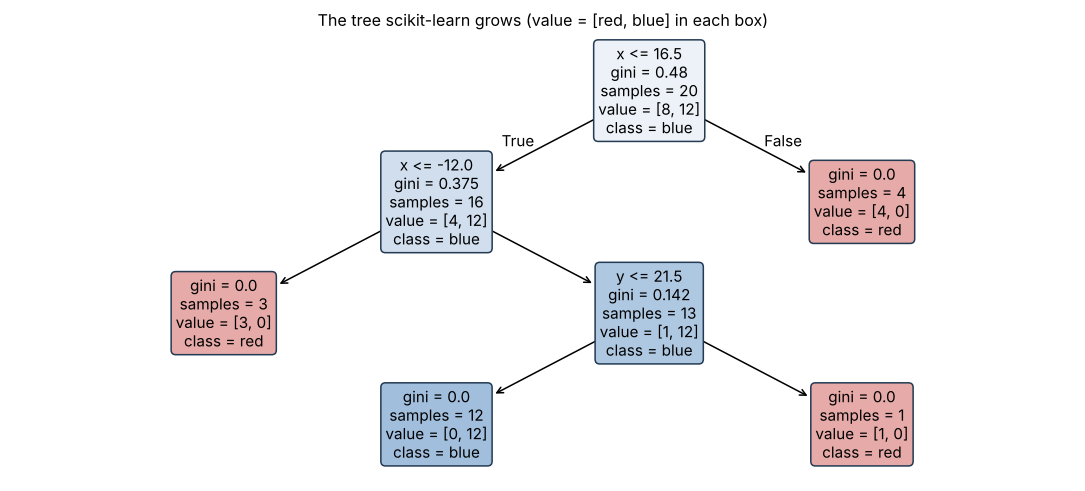

prediction for the new sample (5, 3): blue


In [5]:
toy_tree = DecisionTreeClassifier(random_state=0).fit(X_toy, y_toy)
fig, ax = plt.subplots(figsize=(10, 4.6))
anns = plot_tree(toy_tree, feature_names=["x", "y"], class_names=["red", "blue"],
                 impurity=True, rounded=True, fontsize=10, ax=ax)
# colour each box by its majority class (plot_tree draws nodes in the same order as their ids)
for node_id, ann in enumerate([a for a in anns if "samples" in a.get_text()]):
    counts = toy_tree.tree_.value[node_id][0]
    purity = counts.max() / counts.sum()
    base = np.array([0.78, 0.27, 0.24]) if counts[0] >= counts[1] else np.array([0.18, 0.43, 0.70])
    ann.set_bbox(dict(boxstyle="round", fc=1 - (1 - base) * (purity - 0.5) * 2 * 0.45, ec=LINE))
ax.set_title("The tree scikit-learn grows (value = [red, blue] in each box)", fontsize=10.5)
plt.tight_layout(); plt.show()
print("prediction for the new sample (5, 3):", ["red", "blue"][toy_tree.predict([[5, 3]])[0]])

`scikit-learn` asks the **same three kinds of question** we used by hand ($x \le 17$, $x \le -12$, a cut on $y$), but in a **different order**: it starts with $x \le 16.5$ because that scored the lowest Gini impurity. Both trees classify every training point correctly, and both predict **blue** for the new sample at $(5, 3)$.

Each box shows the question, the Gini impurity of the group, the number of samples, the counts `value = [red, blue]`, and the majority class. Check the numbers against our hand calculation: the root has $G = 0.48$, and the left child after $x \le 16.5$ has $G = 0.375$.

## When should a tree stop growing?

The recipe said "repeat until the groups are pure". Pause and think before reading on.

:::{dropdown} 🤔 What happens if we keep splitting until **every** leaf is pure?
The tree keeps adding questions until each leaf holds just one or two training points. It has then **memorised** the training data, including its noise and its mistakes. It scores perfectly on the training set, but its rules are too specific to work on new samples.

This is **overfitting**, exactly as in the bias–variance chapter. A very deep tree is a **low-bias, high-variance** model.
:::

Here is a noisier two-class dataset (the classic "two moons", 400 points). We let trees grow to different depths:

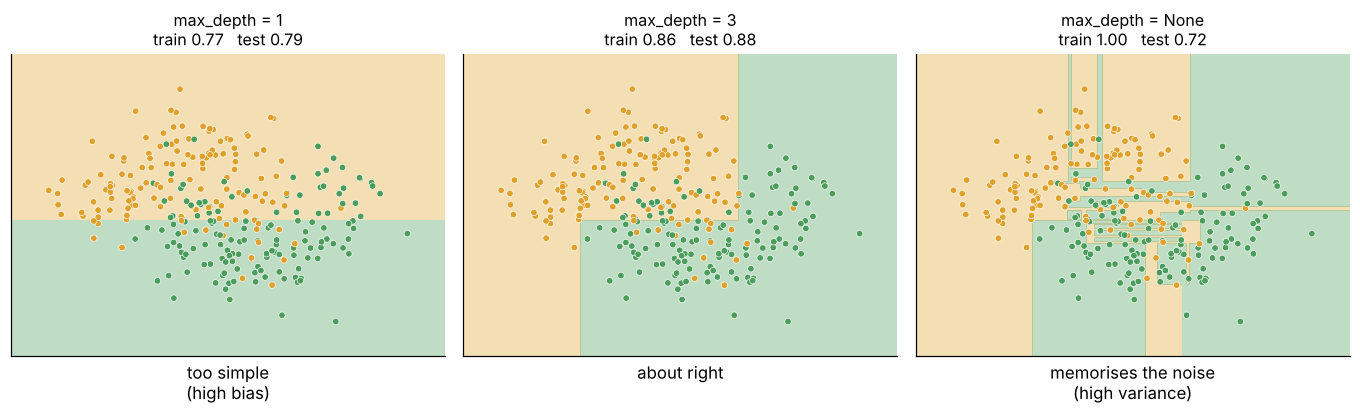

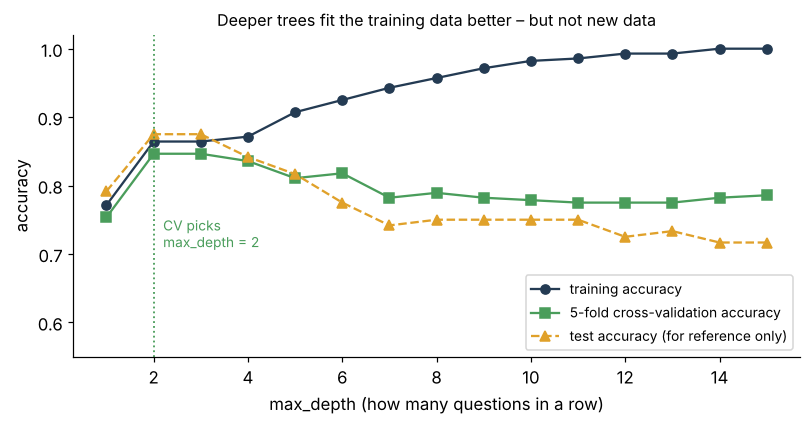

In [6]:
Xm, ym = make_moons(n_samples=400, noise=0.4, random_state=0)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, stratify=ym, random_state=0)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9), sharex=True, sharey=True)
for ax, depth in zip(axes, [1, 3, None]):
    m = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xm_tr, ym_tr)
    plot_regions(ax, m, Xm_tr, ym_tr)
    ax.set_title(f"max_depth = {depth}\ntrain {m.score(Xm_tr, ym_tr):.2f}   test {m.score(Xm_te, ym_te):.2f}",
                 fontsize=10.5)
axes[0].set_xlabel("too simple\n(high bias)"); axes[1].set_xlabel("about right")
axes[2].set_xlabel("memorises the noise\n(high variance)")
plt.tight_layout(); plt.show()

depths = list(range(1, 16))
tr, te, cv = [], [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xm_tr, ym_tr)
    tr.append(m.score(Xm_tr, ym_tr)); te.append(m.score(Xm_te, ym_te))
    cv.append(cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=0), Xm_tr, ym_tr, cv=5).mean())
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(depths, tr, "o-", color=LINE, label="training accuracy")
ax.plot(depths, cv, "s-", color=GREEN, label="5-fold cross-validation accuracy")
ax.plot(depths, te, "^--", color=GOLD, label="test accuracy (for reference only)")
best = depths[int(np.argmax(cv))]
ax.axvline(best, color=GREEN, ls=":", lw=1.2)
ax.text(best + 0.2, 0.71, f"CV picks\nmax_depth = {best}", color=GREEN, fontsize=9)
ax.set_xlabel("max_depth (how many questions in a row)"); ax.set_ylabel("accuracy")
ax.set_ylim(0.55, 1.02); ax.legend(fontsize=9, loc="lower right")
ax.set_title("Deeper trees fit the training data better – but not new data", fontsize=10.5)
plt.tight_layout(); plt.show()

Read the curves from left to right. **Training** accuracy keeps climbing to a perfect 1.0. **Cross-validation** accuracy (our honest estimate of performance on new data) peaks early and then drifts down as the tree starts memorising noise. That is the bias–variance trade-off in one picture.

### Stopping rules (pre-pruning)

We stop a tree from growing too far by setting **hyperparameters** before training. The most useful ones in `scikit-learn`:

| Hyperparameter | What it means | Effect of making it… |
|---|---|---|
| `max_depth` | the most questions in a row | smaller → simpler tree |
| `min_samples_split` | a group must have at least this many samples to be split | larger → simpler tree |
| `min_samples_leaf` | every leaf must keep at least this many samples | larger → simpler, smoother tree |
| `max_leaf_nodes` | the most leaves the tree may have | smaller → simpler tree |
| `min_impurity_decrease` | only split if impurity drops by at least this much | larger → simpler tree |

### Pruning after growing (post-pruning)

Instead of stopping early, we can grow a big tree and then **cut back** the branches that add little. `scikit-learn` does this with **cost-complexity pruning**, controlled by `ccp_alpha`: a larger `ccp_alpha` removes more branches. It plays the same role as the penalty $\lambda$ in Ridge and Lasso: a price paid for complexity.

### How do we choose the values?

Is a minimum of 3 samples per leaf better than 5? We do not guess. We use **cross-validation** on the training set (Week 6) to try several values and keep the one that scores best. The test set is kept aside until the very end.

The chosen tree may leave some leaves **slightly impure**. That is fine: such a leaf predicts its **majority class**, and the class fractions in the leaf give a simple probability estimate. We accept a little impurity on the training data in exchange for a model that is more reliable on future data.

## Trees can predict numbers too

Everything so far was **classification**. A **regression tree** works the same way, with two small changes:

- **Each leaf predicts a number**: the **average** target value of the training samples that land in it.
- **Questions are scored by squared error** instead of Gini. The tree picks the cut that makes the values inside each group as **similar** as possible (lowest variance). In `scikit-learn` this is `criterion="squared_error"`, the default for `DecisionTreeRegressor`.

The result is a **step function**. Below, a regression tree fits made-up hardness measurements that fall as the tempering temperature rises (the numbers are invented, loosely shaped like a tempering curve):

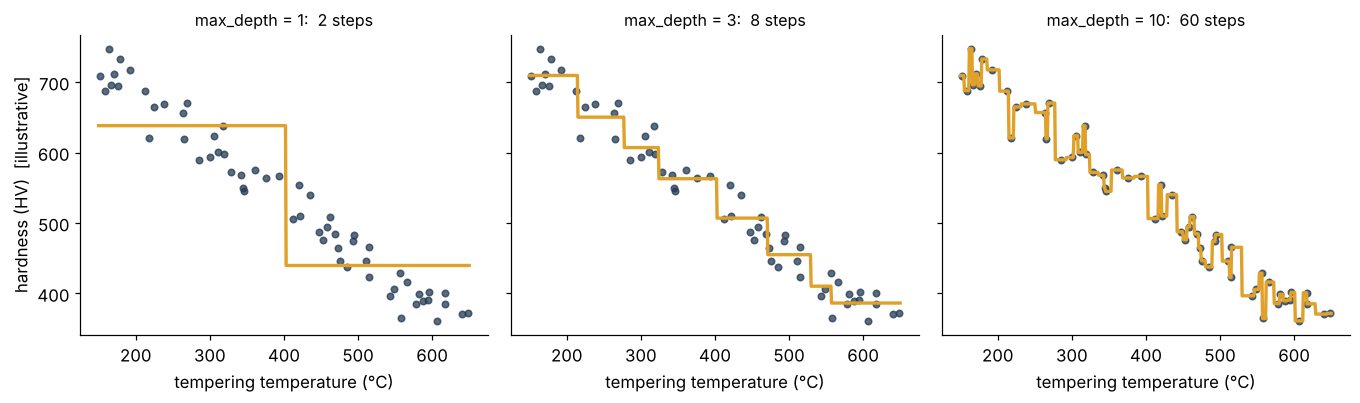

In [7]:
rng = np.random.default_rng(0)
T = np.sort(rng.uniform(150, 650, 60))
HV = 720 - 0.75 * (T - 150) + rng.normal(0, 22, T.size)        # invented data
Tgrid = np.linspace(150, 650, 600).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8), sharey=True)
for ax, depth in zip(axes, [1, 3, 10]):
    reg = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(T.reshape(-1, 1), HV)
    ax.scatter(T, HV, s=18, color=LINE, alpha=0.75)
    ax.plot(Tgrid, reg.predict(Tgrid), color=GOLD, lw=2.2)
    ax.set_title(f"max_depth = {depth}:  {reg.get_n_leaves()} steps", fontsize=10.5)
    ax.set_xlabel("tempering temperature (°C)")
axes[0].set_ylabel("hardness (HV)  [illustrative]")
plt.tight_layout(); plt.show()

With one question the tree can only say "low temperature → hard, high temperature → softer". With three levels it follows the trend in eight steps. With ten levels it fits to individual noisy points, the regression version of overfitting.

Two consequences are worth remembering:

- A regression tree's predictions are always **averages of training values**, so it can never predict a value **higher than the largest** (or **lower than the smallest**) target it was trained on. It cannot extrapolate. This matters a lot in materials discovery, where we often hope to find a material *better* than anything we have measured. We will come back to this in the random forest chapter.
- The step-shaped prediction is not smooth, even when the true relationship is.

## The weak spot: trees are wobbly

Decision trees have one big problem. They are **very sensitive to the exact training data**. If we change a few samples and the first question can change; and because every later question depends on the first, the whole tree can come out different.

Below we grow two full trees on two **random resamples** of the same moons training set:

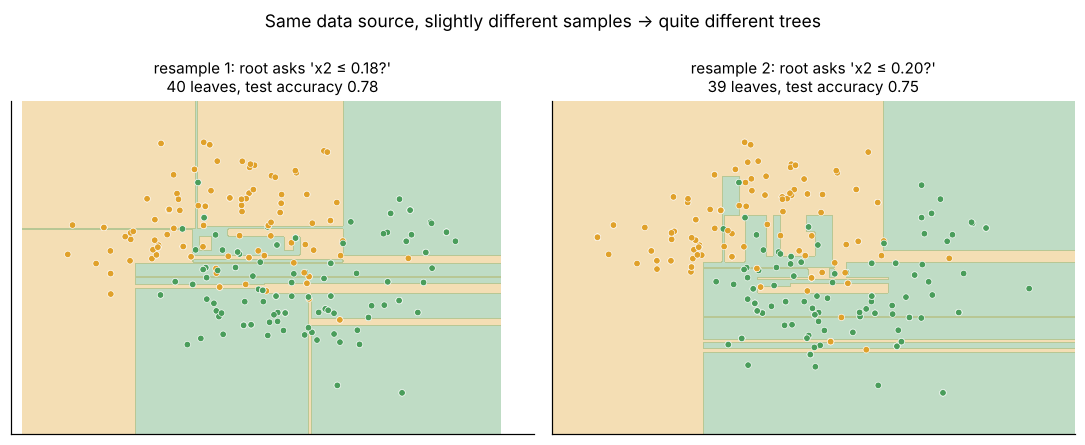

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.1), sharex=True, sharey=True)
names = ["x1", "x2"]
for ax, seed in zip(axes, [1, 2]):
    idx = np.random.default_rng(seed).integers(0, len(Xm_tr), len(Xm_tr))   # resample with replacement
    m = DecisionTreeClassifier(random_state=0).fit(Xm_tr[idx], ym_tr[idx])
    plot_regions(ax, m, Xm_tr[idx], ym_tr[idx])
    f, t = m.tree_.feature[0], m.tree_.threshold[0]
    ax.set_title(f"resample {seed}: root asks '{names[f]} ≤ {t:.2f}?'\n"
                 f"{m.get_n_leaves()} leaves, test accuracy {m.score(Xm_te, ym_te):.2f}", fontsize=10)
fig.suptitle("Same data source, slightly different samples → quite different trees", fontsize=11.5)
plt.tight_layout(); plt.show()

Here both trees happen to start with a similar first question, yet their 40-odd leaves carve up the space quite differently, and they disagree about many regions where the classes overlap: two different "models" from what is really the same data. In statistical language, a deep tree has **high variance**.

This is exactly the problem that **random forests** solve, by growing *many* trees on different resamples and letting them vote. That is the next chapter.

## Good habits with trees

- **No feature scaling needed.** A tree only ever asks "is this feature above or below a threshold?". Any rescaling that keeps the *order* of the values (standardising, changing °C to K, MPa to GPa) moves the thresholds but gives the **same splits and the same predictions**. This is different from k-means, SVMs and Gaussian processes, where scaling was essential. (We check this in the code below.)
- **Categorical features must be turned into numbers.** The theory allows questions like "Is the crystal structure FCC?", but the `scikit-learn` trees only accept numerical input, so use **one-hot encoding** (Week 5) first.
- **Missing values:** recent versions of `scikit-learn` can grow trees on data containing `NaN`. At each split, the samples with a missing value are sent to whichever side gives the better score. That is convenient, but it is **not** a substitute for asking *why* a value is missing, or for the data cleaning we did in Week 4.
- **Trees are easy to read.** You can print the rules (`export_text`) or draw the tree (`plot_tree`) and check that they make physical sense. Few other models let you do that.

## Putting it to work 💪

A complete workflow. Let's practice with some synthetic data: 240 heat-treated steel samples, each described by its **carbon content** (wt%) and **annealing temperature** (°C), labelled **pass** or **fail** against a hardness specification. About 8% of the labels have been deliberately flipped to mimic noisy lab data.

Notice that the two features live on wildly different scales (0.1-1.0 versus 600-1000). We do **not** scale them.

The steps:

1. split into training and test sets (with `stratify=y`),
2. let **cross-validation** choose `max_depth` and `min_samples_leaf`,
3. check the test accuracy, and compare with a tree that is allowed to grow fully,
4. confirm that scaling the features changes nothing,
5. print and draw the rules.

Best settings from CV : {'max_depth': 3, 'min_samples_leaf': 5}
Tuned tree : depth 3,  8 leaves, train 0.944, test 0.867
Full tree  : depth 9, 24 leaves, train 1.000, test 0.867
Same test predictions after scaling? True

|--- carbon_wt% <= 0.48
|   |--- carbon_wt% <= 0.40
|   |   |--- carbon_wt% <= 0.22
|   |   |   |--- class: 0
|   |   |--- carbon_wt% >  0.22
|   |   |   |--- class: 0
|   |--- carbon_wt% >  0.40
|   |   |--- carbon_wt% <= 0.45
|   |   |   |--- class: 1
|   |   |--- carbon_wt% >  0.45
|   |   |   |--- class: 0
|--- carbon_wt% >  0.48
|   |--- anneal_T_C <= 856.01
|   |   |--- anneal_T_C <= 730.56
|   |   |   |--- class: 1
|   |   |--- anneal_T_C >  730.56
|   |   |   |--- class: 1
|   |--- anneal_T_C >  856.01
|   |   |--- carbon_wt% <= 0.75
|   |   |   |--- class: 0
|   |   |--- carbon_wt% >  0.75
|   |   |   |--- class: 1



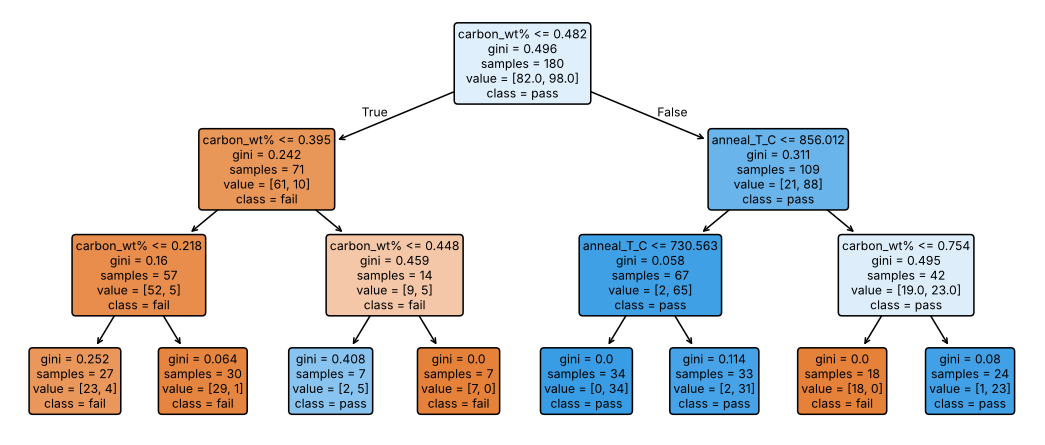

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import StandardScaler

# --- a small, MADE-UP dataset: does a heat-treated steel sample pass a hardness spec? ---
rng = np.random.default_rng(0)
n = 240
carbon   = rng.uniform(0.1, 1.0, n)        # wt% C
anneal_T = rng.uniform(600, 1000, n)       # deg C  (a very different scale from carbon!)
passes = ((carbon > 0.4) & (anneal_T < 850)) | (carbon > 0.75)   # the hidden "true" rule
flip = rng.random(n) < 0.08                # ~8% noisy labels, like real lab data
y = np.where(flip, ~passes, passes).astype(int)                   # 1 = pass, 0 = fail
X = pd.DataFrame({"carbon_wt%": carbon, "anneal_T_C": anneal_T})

# 1. split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=0)

# 2. let 5-fold cross-validation choose how big the tree may grow
grid = {"max_depth": [1, 2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 5, 10]}
search = GridSearchCV(DecisionTreeClassifier(random_state=0), grid, cv=5)
search.fit(X_train, y_train)
tree = search.best_estimator_

# 3. evaluate, and compare with a fully grown tree
full = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print("Best settings from CV :", search.best_params_)
print(f"Tuned tree : depth {tree.get_depth()}, {tree.get_n_leaves():2d} leaves, "
      f"train {tree.score(X_train, y_train):.3f}, test {tree.score(X_test, y_test):.3f}")
print(f"Full tree  : depth {full.get_depth()}, {full.get_n_leaves():2d} leaves, "
      f"train {full.score(X_train, y_train):.3f}, test {full.score(X_test, y_test):.3f}")

# 4. trees don't need scaling: identical predictions on standardised features
scaler = StandardScaler().fit(X_train)
tree_scaled = DecisionTreeClassifier(random_state=0, **search.best_params_).fit(
    scaler.transform(X_train), y_train)
same = np.array_equal(tree.predict(X_test), tree_scaled.predict(scaler.transform(X_test)))
print("Same test predictions after scaling?", same)

# 5. read the rules
print("\n" + export_text(tree, feature_names=list(X.columns)))
fig, ax = plt.subplots(figsize=(12, 5))
plot_tree(tree, feature_names=list(X.columns), class_names=["fail", "pass"],
          filled=True, rounded=True, fontsize=8, ax=ax)
plt.show()

How to read this result:

- **Cross-validation chose a small tree** (`max_depth=3`, at least 5 samples per leaf). The fully grown tree reaches 100% on the training data by memorising the flipped labels, needing 3 times as many levels and 3 times as many leaves.
- **On the test set the two trees score the same here.** With only 60 test samples, a difference of one or two samples is just noise, so we should not read much into it either way. When two models perform about equally, we prefer the **simpler** one: it is easier to read, and its predictions are more stable.
- **Scaling changed nothing**, exactly as promised.
- **The rules make sense.** The tree recovered the hidden rule well: carbon thresholds at 0.40–0.48 wt% (the true rule switches at 0.40; the flipped labels blur the exact edge), an annealing-temperature threshold near 856 °C (true: 850 °C), and a second carbon threshold at 0.75 wt% for samples annealed at high temperature (true: 0.75).
- You may notice a few splits whose two leaves predict the **same class**. These still make the groups purer (the class fractions change), so the tree counts them as improvements even though the predicted label does not change.

## Putting it together

- A **decision tree** predicts by asking a series of yes/no questions, each about **one feature**. It starts at the **root** and ends at a **leaf**.
- At every node the computer tries every possible question and keeps the one that makes the purest groups, measured by the **Gini impurity** (or **entropy / information gain**). This greedy recipe is the **CART** algorithm.
- Regression trees predict the **average** of the training values in each leaf and choose cuts that minimise **squared error**. They cannot extrapolate beyond the training range.
- Grown until every leaf is pure, a tree **overfits**. Control its size with `max_depth`, `min_samples_leaf` and friends, or prune with `ccp_alpha`, and choose those values by **cross-validation**.
- Trees need **no feature scaling** and are **easy to interpret**, but they are **wobbly**: small changes in the data can produce a very different tree. Random forests fix this.

## Check your understanding

:::{dropdown} 1. A group has 6 samples of class A and 2 of class B. What is its Gini impurity?
$G = 1 - (6/8)^2 - (2/8)^2 = 1 - 0.5625 - 0.0625 = 0.375.$
:::

:::{dropdown} 2. Question P splits 10 samples into [5 A, 0 B] and [1 A, 4 B]. Question Q splits them into [3 A, 2 B] and [3 A, 2 B]. Which question will the tree choose?
P: the left child has $G = 0$; the right child has $G = 1 - 0.2^2 - 0.8^2 = 0.32$; weighted $= 0.5 \times 0 + 0.5 \times 0.32 = 0.16$.
Q: both children have $G = 1 - 0.6^2 - 0.4^2 = 0.48$; weighted $= 0.48$.
**P** has the lower impurity, so the tree chooses P. (Q has not separated anything at all: the children are just as mixed as the parent.)
:::

:::{dropdown} 3. Your tree scores 100% on the training data and 70% on the test data. What is going on, and name two settings you could change?
The tree is **overfitting**: it has memorised the training data. Make it simpler, for example by lowering `max_depth`, raising `min_samples_leaf` or `min_samples_split`, or using cost-complexity pruning (`ccp_alpha`). Choose the values with cross-validation.
:::

:::{dropdown} 4. A colleague standardises all features before training a decision tree "to be safe". Will this change the predictions?
No. A tree only compares each feature with a threshold, so any order-preserving rescaling gives the same splits and the same predictions. Standardising does no harm, but it does nothing either. (It *does* matter for SVMs, k-means and Gaussian processes.)
:::

:::{dropdown} 5. A regression tree is trained on alloys with yield strengths between 200 and 900 MPa. Can it ever predict 1100 MPa for a new alloy?
No. Each leaf predicts the **average** of training values, so every prediction lies within the range of the training targets (here, at most 900 MPa). Trees, and forests of trees, cannot extrapolate.
:::

:::{dropdown} 6. Why can't a single question in a decision tree draw a sloping boundary such as $y = x$?
Each question uses **one feature** and one threshold, so every cut is parallel to an axis. A sloping boundary has to be approximated by a staircase of many axis-parallel cuts.
:::

:::{seealso} Where these ideas come from
- Breiman, L., Friedman, J. H., Olshen, R. A. & Stone, C. J. (1984). *Classification and Regression Trees.* Wadsworth. The CART algorithm, the Gini criterion and cost-complexity pruning.
- Quinlan, J. R. (1986). Induction of decision trees. *Machine Learning*, 1, 81–106. Entropy and information gain for growing trees (the ID3 algorithm).
- James, G., Witten, D., Hastie, T. & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.), Chapter 8: Tree-Based Methods. Free to download from the authors' website.
- The scikit-learn User Guide, section *Decision Trees*, covers `DecisionTreeClassifier`, `DecisionTreeRegressor`, the stopping and pruning settings, and missing-value support.
:::